In [1]:
pip install pandas numpy scikit-learn matplotlib seaborn

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 23.3.1 -> 26.2.2
[notice] To update, run: C:\Program Files\Python311\python.exe -m pip install --upgrade pip


### Phase 2 — Data collection

In [2]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import seaborn as sns
from sklearn.datasets import fetch_openml

housing = fetch_openml(name='house_prices', as_frame=True, parser='auto')

df = housing.frame
print(df.shape)
print(df.dtypes.value_counts())
df.head()

(1460, 81)
object     43
int64      35
float64     3
Name: count, dtype: int64


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


### Phase 3 — Explanatory Data Analysis (EDA)

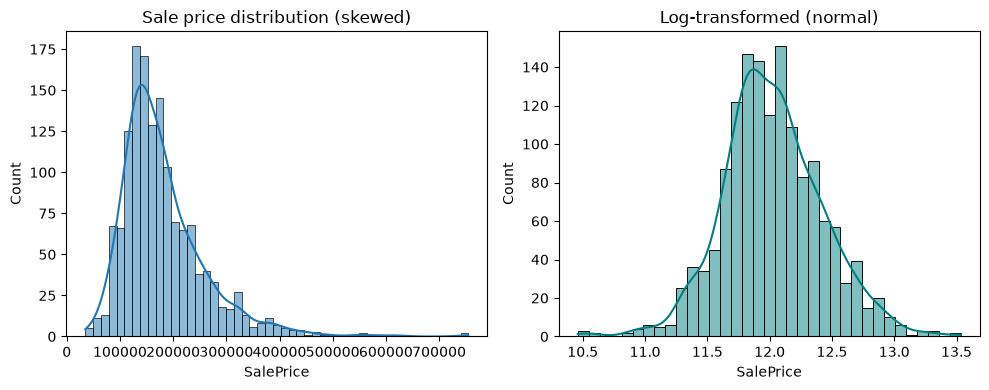

PoolQC          1453
MiscFeature     1406
Alley           1369
Fence           1179
FireplaceQu      690
LotFrontage      259
GarageType        81
GarageYrBlt       81
GarageFinish      81
GarageQual        81
GarageCond        81
BsmtExposure      38
BsmtFinType2      38
BsmtFinType1      37
BsmtCond          37
BsmtQual          37
MasVnrArea         8
MasVnrType         8
Electrical         1
dtype: int64
SalePrice       1.000000
OverallQual     0.790982
GrLivArea       0.708624
GarageCars      0.640409
GarageArea      0.623431
TotalBsmtSF     0.613581
1stFlrSF        0.605852
FullBath        0.560664
TotRmsAbvGrd    0.533723
YearBuilt       0.522897
Name: SalePrice, dtype: float64


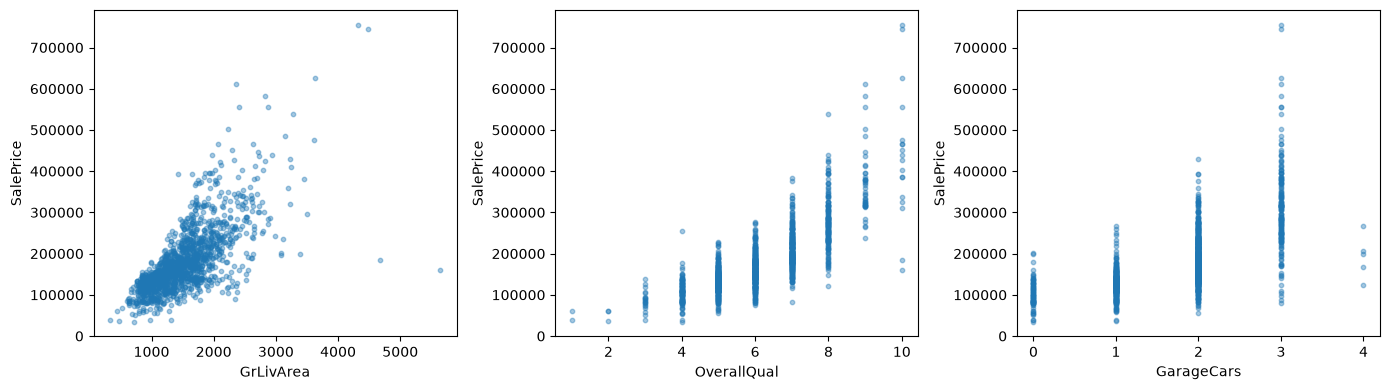

In [3]:
# --- 1. Target distribution ---
df["SalePrice"] = df["SalePrice"].astype(float)

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
sns.histplot(df["SalePrice"], kde=True)
plt.title("Sale price distribution (skewed)")

plt.subplot(1, 2, 2)
sns.histplot(np.log1p(df["SalePrice"]), kde=True, color="teal")
plt.title("Log-transformed (normal)")
plt.tight_layout()
plt.show()

# --- 2. Missing values ---
missing = df.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)
print(missing.head(20))

# --- 3. Correlation with target ---
num_cols = df.select_dtypes(include=np.number).columns
corr = df[num_cols].corr()["SalePrice"].sort_values(ascending=False)
print(corr.head(10))   # top correlated features

# --- 4. Key scatterplots ---
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col in zip(axes, ["GrLivArea", "OverallQual", "GarageCars"]):
    ax.scatter(df[col], df["SalePrice"], alpha=0.4, s=10)
    ax.set_xlabel(col)
    ax.set_ylabel("SalePrice")
plt.tight_layout()
plt.show()

### Phase 4 - Preprocessing Pipeline

In [4]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
import numpy as np
import pandas as pd

# Log-transform target (reduces skew, improves model fit)
y = np.log1p(df['SalePrice'])
X = df.drop(columns=['SalePrice'])

# Split first - never fit preprocessors on test data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Separate numerical and categorical columns
nums_cols = X_train.select_dtypes(include = np.number).columns.tolist()
cat_cols = X_train.select_dtypes(include = "object").columns.tolist()

# Numeric: impute median -> scale
num_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy = "median")),
    ("scaler", StandardScaler()),
])

# Categorical: impute most frequent -> one-hot encode
cat_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy='most_frequent')),
    ("encode", OneHotEncoder(handle_unknown='ignore', sparse_output=False)),
])

preprocessor = ColumnTransformer([
    ("num", num_pipeline, nums_cols),
    ("cat", cat_pipeline, cat_cols)
])

### Phase 5 - Model Building and Evaluation

In [5]:
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_squared_error, r2_score

models = {
    "Ridge": Ridge(alpha=10),
    "Random Forest": RandomForestRegressor(n_estimators=200, random_state=42),
    "Gradient Boosting": GradientBoostingRegressor(n_estimators=300, learning_rate=0.05, random_state=42),
}

results = {}
for name, model in models.items():
    pipe = Pipeline([("prep", preprocessor), ("model", model)])
    pipe.fit(X_train, y_train)

    preds = pipe.predict(X_test)
    rmse = np.sqrt(mean_squared_error(y_test, preds))
    r2 = r2_score(y_test, preds)
    results[name] = {"RMSE (log)": round(rmse, 4), "R2": round(r2, 4)}
    print(f"{name:25s} → RMSE: {rmse:.4f}  R²: {r2:.4f}")

# Expected output (approx):
# Ridge                     → RMSE: 0.1412  R²: 0.878
# Random Forest             → RMSE: 0.1301  R²: 0.896
# Gradient Boosting         → RMSE: 0.1198  R²: 0.912  ← best

# --- Tune best model with GridSearchCV ---
from sklearn.model_selection import GridSearchCV

param_grid = {
    "model__n_estimators": [200, 300],
    "model__learning_rate": [0.05, 0.1],
    "model__max_depth": [3, 5],
}

best_pipe = Pipeline([("prep", preprocessor),
                      ("model", GradientBoostingRegressor(random_state=42))])

gs = GridSearchCV(best_pipe, param_grid, cv=5, scoring='neg_root_mean_squared_error',
                  n_jobs=-1)
gs.fit(X_train, y_train)
print("Best Params:", gs.best_params_)

Ridge                     → RMSE: 0.1359  R²: 0.9011
Random Forest             → RMSE: 0.1471  R²: 0.8840
Gradient Boosting         → RMSE: 0.1337  R²: 0.9042
Best Params: {'model__learning_rate': 0.05, 'model__max_depth': 3, 'model__n_estimators': 300}


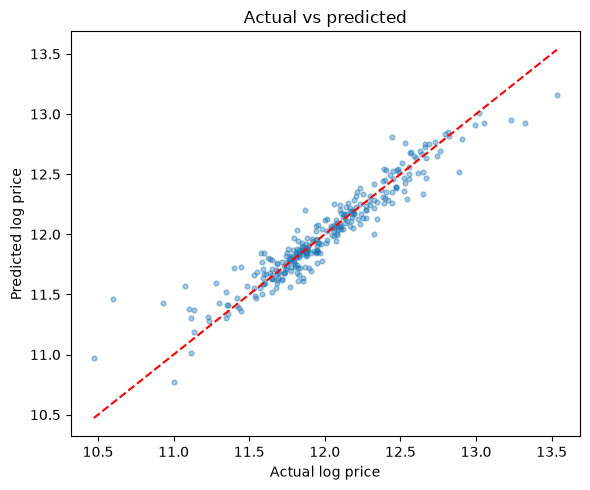

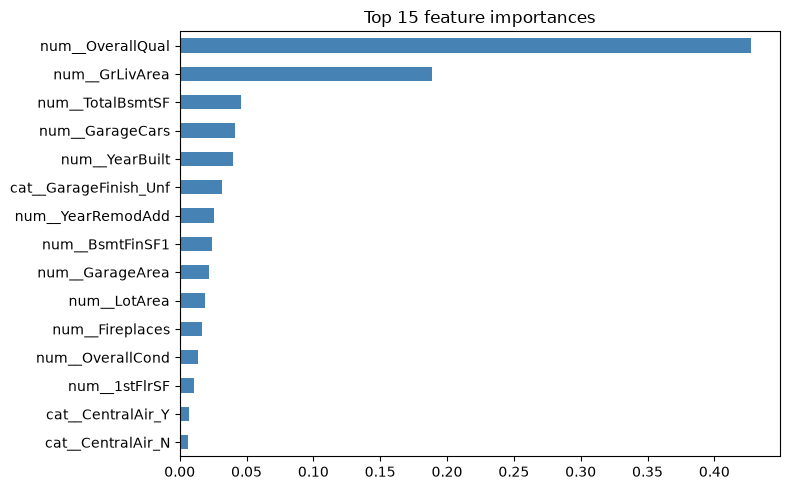

Mean predicted: $176,129
Mean actual:    $178,840


In [6]:
final_model = gs.best_estimator_
preds = final_model.predict(X_test)

# --- 1. Actual vs predicted ---
plt.figure(figsize=(6, 5))
plt.scatter(y_test, preds, alpha=0.4, s=12)
plt.plot([y_test.min(), y_test.max()],
         [y_test.min(), y_test.max()], "r--")
plt.xlabel("Actual log price")
plt.ylabel("Predicted log price")
plt.title("Actual vs predicted")
plt.tight_layout()
plt.show()

# --- 2. Feature importance (top 15) ---
gb_model = final_model.named_steps["model"]

# ✅ Get feature names directly from the fitted preprocessor
# This is always accurate — no manual counting needed
all_cols = final_model.named_steps["prep"].get_feature_names_out()

importances = pd.Series(gb_model.feature_importances_, index=all_cols)
top15       = importances.nlargest(15)

plt.figure(figsize=(8, 5))
top15.sort_values().plot(kind="barh", color="steelblue")
plt.title("Top 15 feature importances")
plt.tight_layout()
plt.show()

# --- 3. Convert predictions back to dollars ---
pred_prices   = np.expm1(preds)          # reverse log1p
actual_prices = np.expm1(y_test.values)
print(f"Mean predicted: ${pred_prices.mean():,.0f}")
print(f"Mean actual:    ${actual_prices.mean():,.0f}")